In [1]:
#Importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
#Mounting google drive since I have uploaded the csv file on my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Loading the data
df = pd.read_csv('/content/drive/MyDrive/CSV/austo_automobile  (1).csv')

In [4]:
#Checking the structure of the data
df.head()

,Age,Gender,Profession,Marital_status,Education,No_of_Dependents,Personal_loan,House_loan,Partner_working,Salary,Partner_salary,Total_salary,Price,Make
0,53,Male,Business,Married,Post Graduate,4,No,No,Yes,99300,70700.0,170000,61000,SUV
1,53,Femal,Salaried,Married,Post Graduate,4,Yes,No,Yes,95500,70300.0,165800,61000,SUV
2,53,Female,Salaried,Married,Post Graduate,3,No,No,Yes,97300,60700.0,158000,57000,SUV
3,53,Female,Salaried,Married,Graduate,2,Yes,No,Yes,72500,70300.0,142800,61000,SUV
4,53,Male,Salaried,Married,Post Graduate,3,No,No,Yes,79700,60200.0,139900,57000,SUV


df.head() showed realistic values. Notice typo in Gender where "Femal" appears needs correction. All sample rows have "SUV" in Make, hinting at class imbalance we’ll verify later.


In [5]:
df.shape

(1581, 14)

1581 rows × 14 columns means 1581 customer records, 14 variables.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1581 entries, 0 to 1580
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1581 non-null   int64  
 1   Gender            1528 non-null   object 
 2   Profession        1581 non-null   object 
 3   Marital_status    1581 non-null   object 
 4   Education         1581 non-null   object 
 5   No_of_Dependents  1581 non-null   int64  
 6   Personal_loan     1581 non-null   object 
 7   House_loan        1581 non-null   object 
 8   Partner_working   1581 non-null   object 
 9   Salary            1581 non-null   int64  
 10  Partner_salary    1475 non-null   float64
 11  Total_salary      1581 non-null   int64  
 12  Price             1581 non-null   int64  
 13  Make              1581 non-null   object 
dtypes: float64(1), int64(5), object(8)
memory usage: 173.1+ KB


Confirms the dtypes above and reveals non-null counts:
All columns except Gender (1528 non-null) and Partner_salary (1475 non-null)
are complete. All columns seem to have appropriate data types

In [7]:
df['Gender'].value_counts()

,count
Gender,
Male,1199
Female,327
Femal,1
Femle,1


In [8]:
df['Gender'].isnull().sum()

np.int64(53)

**As we can see in the gender column there is missing data, we will drop all those rows and we can also see typos like "Femal" and "Femle" we will fix that too after that**

In [9]:
df.dropna(subset=['Gender'],axis=0,inplace=True)
df.reset_index(drop=True,inplace=True)

In [10]:
df['Gender'].isnull().sum()

np.int64(0)

In [11]:
#Fixing the typos

df['Gender'] = df['Gender'].replace({
    'Femal': 'Female',
    'Femle': 'Female'
})

In [12]:
df['Gender'].value_counts()

,count
Gender,
Male,1199
Female,329


**Now our Gender column is fixed**

In [13]:
print(df['Partner_salary'].isnull().sum())

103


**As we can see there are null values in the column "Partner_Salary" but there are no null values in the columns "Partner_working", "Salary", and "Total_salary". To fix "Partner_salary" we will check if "Partner_working" = No then "Partner_salary" = 0 and if "Partner_working" = Yes we will do Partner_salary = Total_salary - Salary**

In [14]:
mask_no_work = (df['Partner_working'] == 'No') & (df['Partner_salary'].isna())
df.loc[mask_no_work, 'Partner_salary'] = 0

In [15]:
mask_working_missing = (df['Partner_working'] == 'Yes') & (df['Partner_salary'].isna())
df.loc[mask_working_missing, 'Partner_salary'] = (
    df.loc[mask_working_missing, 'Total_salary'] - df.loc[mask_working_missing, 'Salary'])

In [16]:
print(df['Partner_salary'].isnull().sum())

0


In [17]:
(df['Partner_salary']<0).sum() #Checking if there is any negative value because of substraction

np.int64(0)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1528 entries, 0 to 1527
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1528 non-null   int64  
 1   Gender            1528 non-null   object 
 2   Profession        1528 non-null   object 
 3   Marital_status    1528 non-null   object 
 4   Education         1528 non-null   object 
 5   No_of_Dependents  1528 non-null   int64  
 6   Personal_loan     1528 non-null   object 
 7   House_loan        1528 non-null   object 
 8   Partner_working   1528 non-null   object 
 9   Salary            1528 non-null   int64  
 10  Partner_salary    1528 non-null   float64
 11  Total_salary      1528 non-null   int64  
 12  Price             1528 non-null   int64  
 13  Make              1528 non-null   object 
dtypes: float64(1), int64(5), object(8)
memory usage: 167.3+ KB


In [19]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1528.0,NaN,NaN,NaN,32.013743,8.45167,22.0,25.0,29.0,38.0,54.0
Gender,1528,2,Male,1199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profession,1528,2,Salaried,864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_status,1528,2,Married,1395,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,1528,2,Post Graduate,951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
No_of_Dependents,1528.0,NaN,NaN,NaN,2.448953,0.943741,0.0,2.0,2.0,3.0,4.0
Personal_loan,1528,2,Yes,768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
House_loan,1528,2,No,1018,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner_working,1528,2,Yes,838,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,1528.0,NaN,NaN,NaN,60453.403141,14682.669181,30000.0,51900.0,59500.0,72000.0,99300.0


**Key Observations**

Age Distribution:
The average age is 32, with most individuals between 25 and 38. The range (22–54) shows a fairly young to mid-career working population with no extreme outliers.

Dependents:
Most people have 2 to 3 dependents. No one has more than 4, so the data is realistic and clean.

Salary:
Median salary is ₹59,500 with a modest spread. The upper limit is ₹99,300, indicating no massive income outliers. Distribution is mildly right-skewed due to a few high earners.

Partner’s Salary:
The partner salary is zero for a significant number of rows (at least 25% of the dataset), matching with many entries where Partner_working = No. Among working partners, the income varies widely — from low to fairly high (up to ₹80,500).

Total Salary:
This is just the sum of the main and partner salaries. It ranges from ₹30,600 to ₹1,71,000, indicating a few high-income households. Because it's a derived column, you should avoid using it in modeling along with Salary and Partner_salary to prevent redundancy.

Price of Purchased Product (likely a vehicle):
The average price is ₹36,023, median ₹32,000. The data is skewed right — 75% of the population buys under ₹47,000. This means most customers opt for mid-range pricing and only a few go for expensive options (up to ₹70,000).

Sedan is the most purchased Make



# **Univariate Analysis**

*   Histograms & box-plots for numeric columns.

*   For categorical columns we use bar (count) plots or a frequency table.







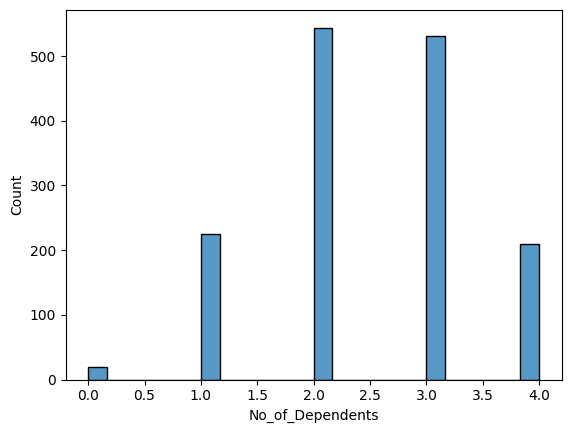

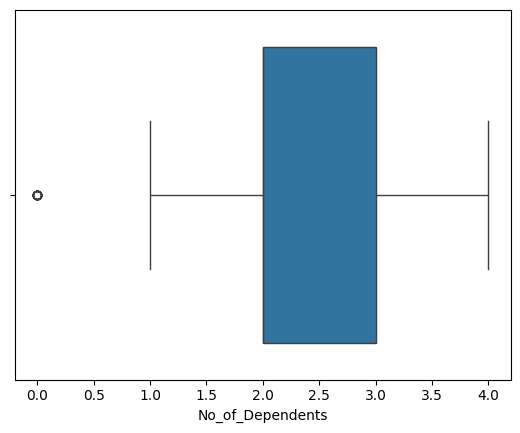

In [20]:
sns.histplot(data=df, x='No_of_Dependents');
plt.show()

sns.boxplot(x=df['No_of_Dependents']);
plt.show()

Nearly two-thirds of customers support 2–3 dependents, suggesting mid-sized family units dominate the target market. So, marketing messages framed around ‘family needs’ will resonate with the vast majority.

Every value lies inside 0-4; keep as-is.

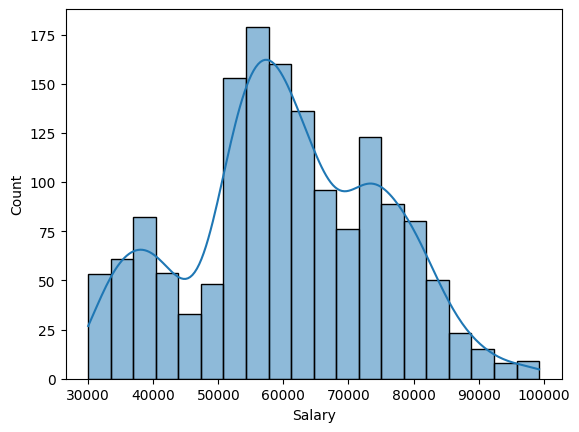

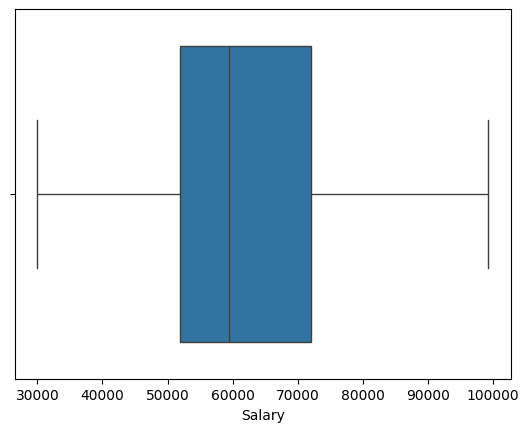

In [21]:
sns.histplot(data=df, x='Salary',kde=True);
plt.show()

sns.boxplot(x=df['Salary']);
plt.show()

The salary distribution is unimodal and slightly right-skewed, with most customers earning between ₹55,000 and ₹65,000. The median salary is ₹59,500, and the spread of salaries is moderate, ranging from ₹30,000 to ₹99,000. There are no salary outliers, indicating a clean and well-bounded dataset. This implies a predominantly mid-income customer base, useful for setting target price bands for products.

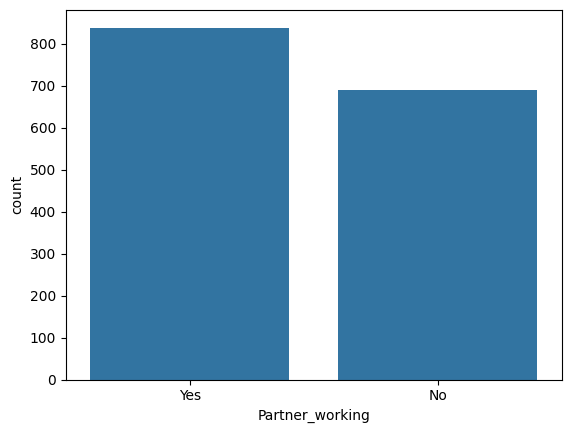

,Count,Percent
Partner_working,,
Yes,838,54.842932
No,690,45.157068


In [22]:
sns.countplot(data=df, x='Partner_working');
plt.show()

freq = df['Partner_working'].value_counts()
pct  = df['Partner_working'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

A slim majority (≈ 55 %) of customers have a working partner. This aligns with the earlier Partner _salary distribution, where ≈ 45 % of partners earned no income. We’ll revisit this split when analyzing how partner income influences vehicle buying trends.

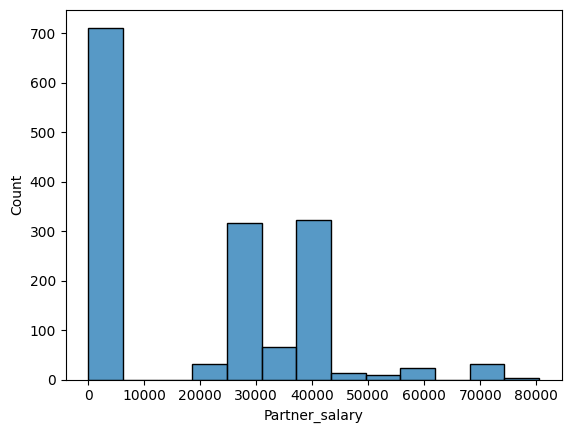

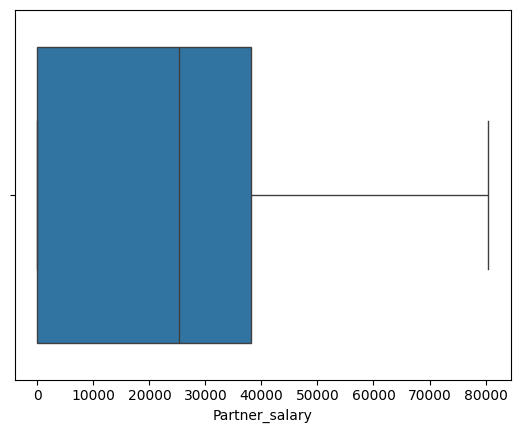

In [23]:
sns.histplot(data=df, x='Partner_salary');
plt.show()

sns.boxplot(x=df['Partner_salary']);
plt.show()

The distribution of Partner_salary is heavily right-skewed, with nearly ≈ 45 % of entries showing zero income — consistent with the Partner_working column. Among working partners, salary clusters around ₹30,000–₹40,000, with a few earning above ₹60,000. This split structure suggests the need to analyze this variable conditionally (i.e., split by working status) to avoid misleading central tendencies. No outliers were found, and the data appears valid.

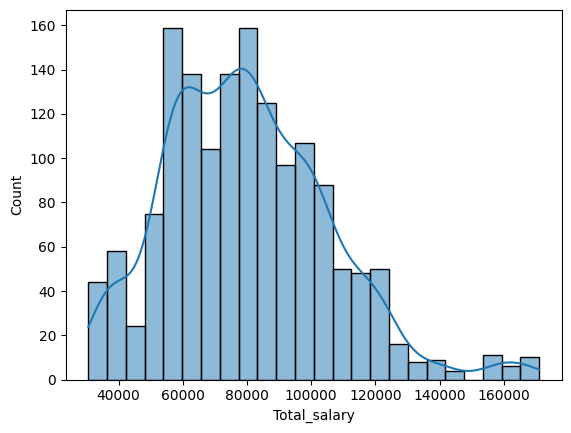

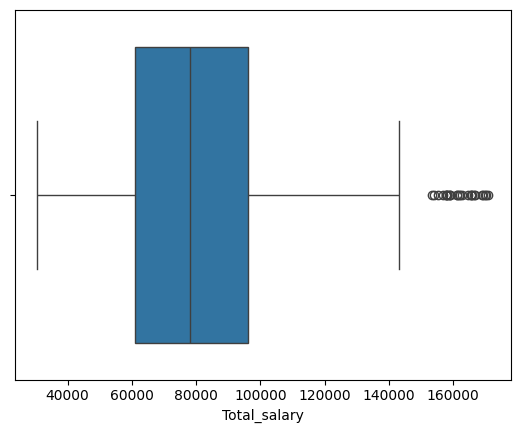

In [24]:
sns.histplot(data=df, x='Total_salary',kde=True);
plt.show()

sns.boxplot(x=df['Total_salary']);
plt.show()

In [25]:
Q1 = df['Total_salary'].quantile(0.25)
Q3 = df['Total_salary'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Total_salary'] < lower_bound) | (df['Total_salary'] > upper_bound)]

print("🔍 Outlier rows:")
display(outliers[['Total_salary', 'Partner_working', 'Profession']])

print("\n Partner_working counts among outliers:")
print(outliers['Partner_working'].value_counts(dropna=False))

print("\n Profession counts among outliers:")
print(outliers['Profession'].value_counts(dropna=False))

print("\n Crosstab (Partner_working vs Profession) among outliers:")
print(pd.crosstab(outliers['Partner_working'], outliers['Profession']))

🔍 Outlier rows:


,Total_salary,Partner_working,Profession
0,170000,Yes,Business
1,165800,Yes,Salaried
2,158000,Yes,Salaried
17,165700,Yes,Salaried
18,162900,Yes,Business
19,159000,Yes,Salaried
27,169000,Yes,Salaried
28,165600,Yes,Salaried
29,161100,Yes,Business
39,166900,Yes,Salaried



 Partner_working counts among outliers:
Partner_working
Yes    27
Name: count, dtype: int64

 Profession counts among outliers:
Profession
Salaried    19
Business     8
Name: count, dtype: int64

 Crosstab (Partner_working vs Profession) among outliers:
Profession       Business  Salaried
Partner_working                    
Yes                     8        19


Total_salary is right-skewed, with the bulk of household incomes between ₹60 k and ₹100 k and a small affluent tail up to ₹171 k. There are some high-income outliers, but they appear genuine and will be retained since every outlier is two income household and 19 are salaried and 8 are business as income source so the outliers are very plausible.

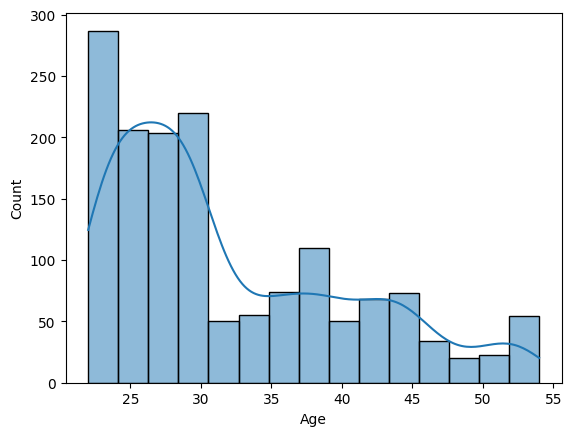

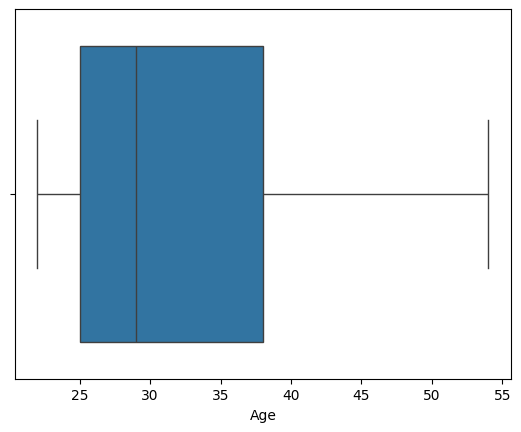

In [26]:
sns.histplot(data=df, x='Age',kde=True);
plt.show()

sns.boxplot(x=df['Age']);
plt.show()

Age is right-skewed: more than half of customers are between 25 – 38 years old, with a modal cluster at 23-25 years. A smaller, secondary cluster appears around 40 years, and the distribution tapers off by 54 years. No age outliers are present, indicating clean data. Marketing strategies should primarily target the 25-35 demographic while keeping an eye on the mid-career niche (38-45)

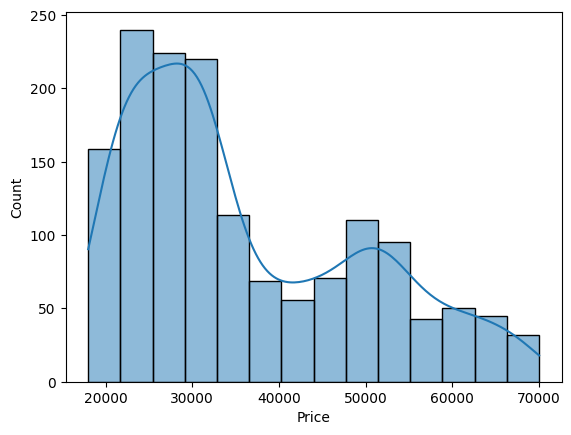

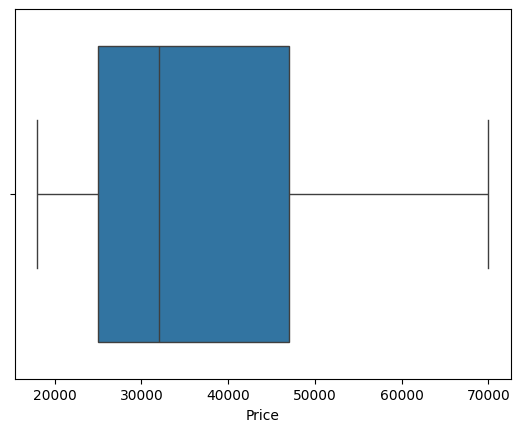

In [27]:
sns.histplot(data=df, x='Price',kde=True);
plt.show()

sns.boxplot(x=df['Price']);
plt.show()

Vehicle Price is right-skewed, with a primary concentration between ₹25 k–35 k and a smaller premium cluster around ₹50 k. The median purchase price is ₹32 k and 75 % of purchases cost <= ₹47 k. No statistical outliers appear, indicating clean, plausible pricing data. The distribution suggests two clear customer segments budget and mid-premium which can guide differentiated marketing or financing offers.

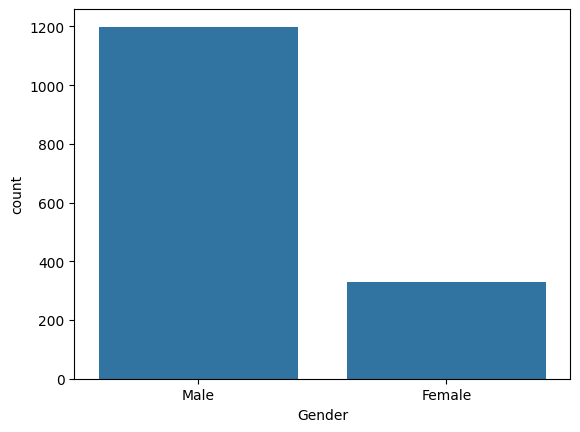

,Count,Percent
Gender,,
Male,1199,78.468586
Female,329,21.531414


In [28]:
sns.countplot(data=df, x='Gender');
plt.show()

freq = df['Gender'].value_counts()
pct  = df['Gender'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

The dataset is 78 % male and 22 % female, highlighting a substantial gender imbalance. All subsequent analyses involving gender will need to account for this skew. This disproportion also frames our first business question whether men truly show a stronger preference for SUVs than women by providing the base rates for comparison.

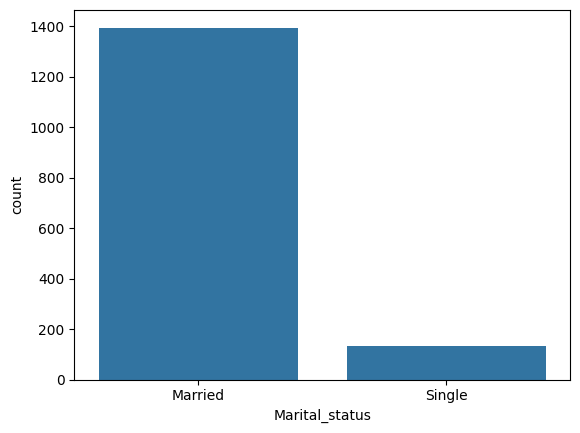

,Count,Percent
Marital_status,,
Married,1395,91.295812
Single,133,8.704188


In [29]:
sns.countplot(data=df, x='Marital_status');
plt.show()

freq = df['Marital_status'].value_counts()
pct  = df['Marital_status'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

The dataset is overwhelmingly composed of married individuals (91.3%), with only 8.7% reporting as single. This aligns with prior findings such as the high number of dependents and the presence of working partners.

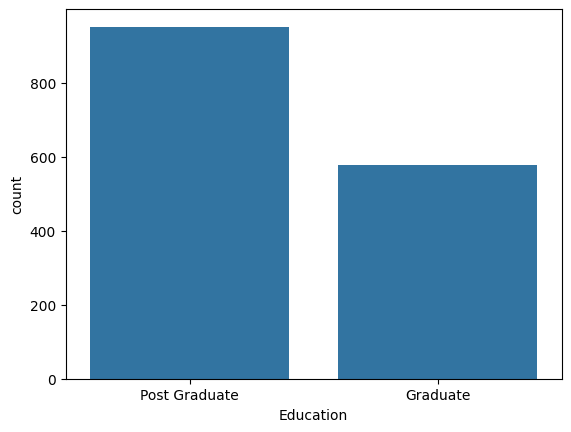

,Count,Percent
Education,,
Post Graduate,951,62.23822
Graduate,577,37.76178


In [30]:
sns.countplot(data=df, x='Education');
plt.show()

freq = df['Education'].value_counts()
pct  = df['Education'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

A majority of customers (62.2%) hold postgraduate degrees, while the remaining 37.8% have undergraduate qualifications. The dataset represents a well educated audience, likely to value advanced product features, financing plans, and long-term brand value. The education variable is balanced enough to allow subgroup comparisons in spending or loan preferences.

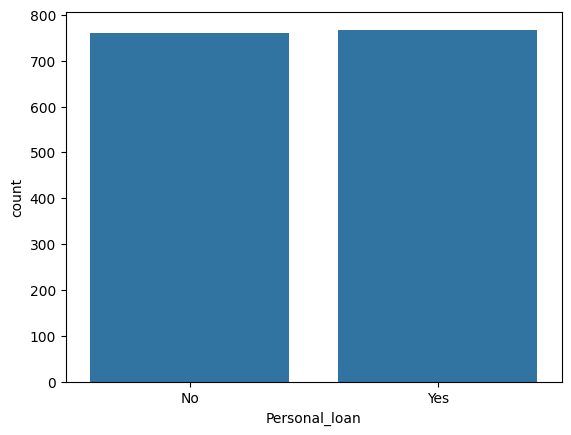

,Count,Percent
Personal_loan,,
Yes,768,50.26178
No,760,49.73822


In [31]:
sns.countplot(data=df, x='Personal_loan');
plt.show()

freq = df['Personal_loan'].value_counts()
pct  = df['Personal_loan'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

Half the customers in the dataset (50.3%) have taken a personal loan, indicating strong usage of financing mechanisms in vehicle purchases. The near-even distribution makes this a valuable categorical variable for comparative analysis across other dimensions such as salary, car price, or education level.

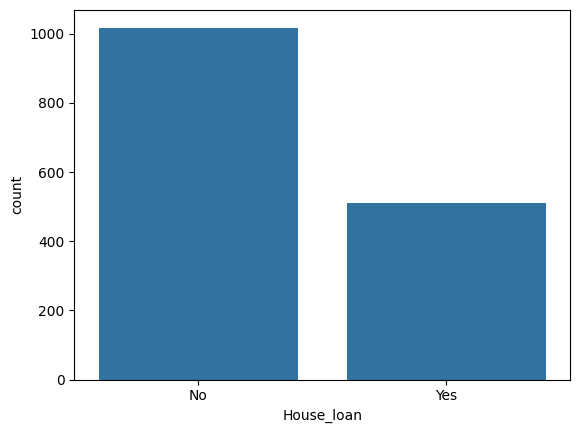

,Count,Percent
House_loan,,
No,1018,66.623037
Yes,510,33.376963


In [32]:
sns.countplot(data=df, x='House_loan');
plt.show()

freq = df['House_loan'].value_counts()
pct  = df['House_loan'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

Roughly one-third (33.4%) of the customers have an existing house loan, while two-thirds do not. This distinction can be valuable when exploring risk segmentation, purchasing power, or cross-loan behavior. Customers without a house loan may have more disposable income for automobile spending, while those with home loans might rely more on financing

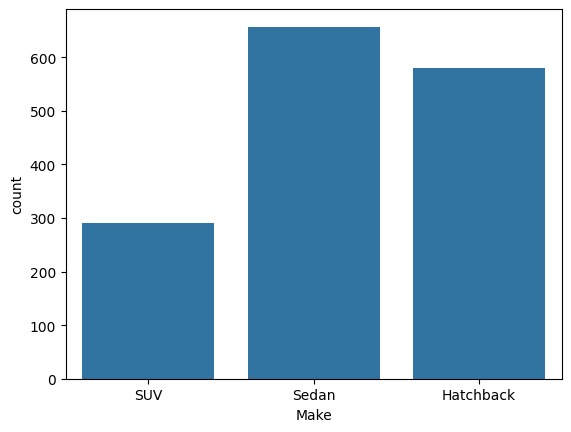

,Count,Percent
Make,,
Sedan,657,42.997382
Hatchback,580,37.958115
SUV,291,19.044503


In [33]:
sns.countplot(data=df, x='Make');
plt.show()

freq = df['Make'].value_counts()
pct  = df['Make'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

The most common vehicle type purchased is Sedan (43%), followed by Hatchback (38%). SUVs make up the smallest share (19%), indicating they are a less popular choice among the overall customer base. This makes the Make variable an important target for subgroup analysis — particularly across Gender and Profession — to see whether SUV preference varies by demographic.

# **Bivariate Analysis**

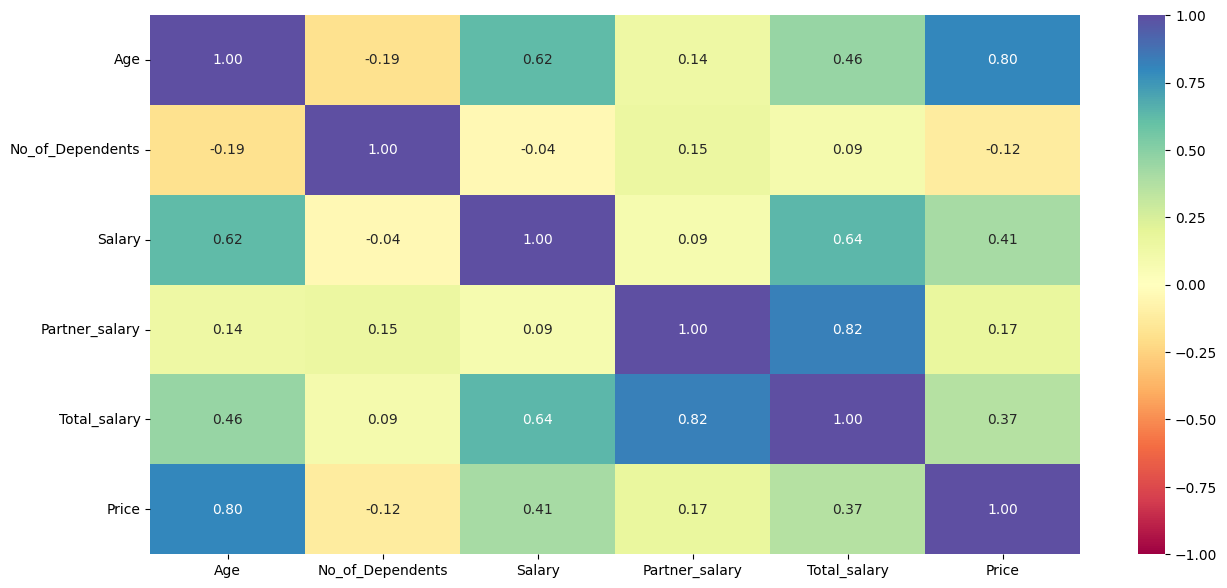

In [34]:
num_var = ['Age','No_of_Dependents','Salary','Partner_salary','Total_salary', 'Price']
corr = df[num_var].corr()


plt.figure(figsize=(15, 7))
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

# We dropped Total_salary to avoid multicollinearity, as it is a derived variable created by summing Salary and Partner_salary. Keeping both base variables allows for more granular analysis.

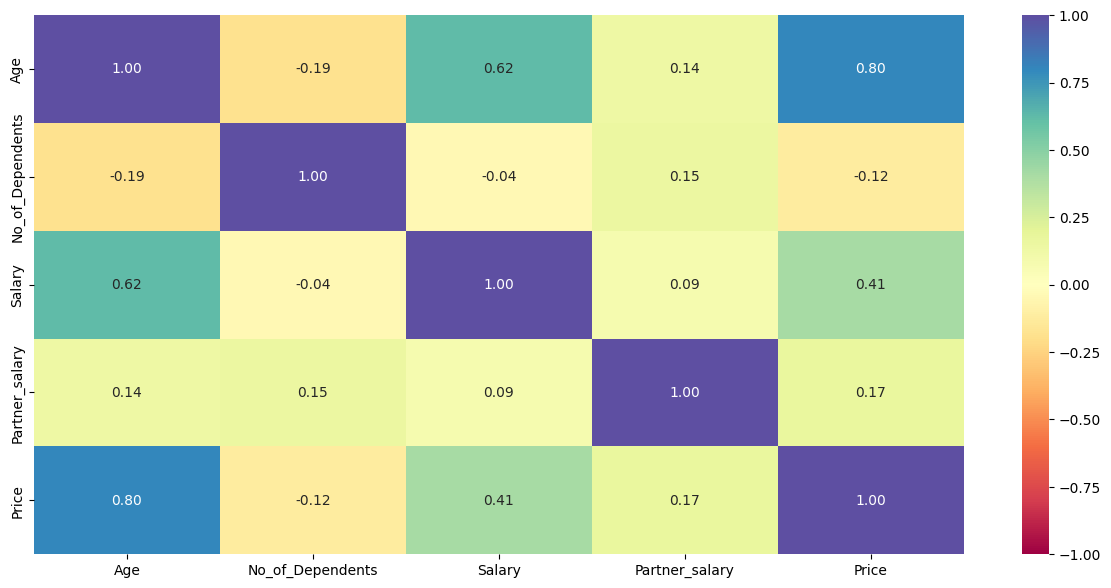

In [35]:
num_var = ['Age','No_of_Dependents','Salary','Partner_salary', 'Price']
corr = df[num_var].corr()


plt.figure(figsize=(15, 7))
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

**Observations & Insights:**

*Age vs Price*

Correlation coefficient: +0.80

Insight: Strongest positive correlation in the dataset. Older customers tend to buy significantly more expensive vehicles. Likely linked to financial maturity and purchasing power.

*Salary vs Price*

Correlation coefficient: +0.41

Insight: Moderate correlation; higher salary is associated with higher car prices, though other variables (e.g., age, loan status) also contribute.

*Partner Salary vs Price*

Correlation coefficient: +0.17

Insight: Weak correlation. A working partner has minimal direct impact on the price of the car purchased by the individual.

*Salary vs Age*

Correlation coefficient: +0.62

Insight: Expected trend — older individuals typically earn more, likely due to career progression.

*No. of Dependents vs Other Variables*

Very weak or negligible correlations (|r| < 0.20)

Insight: Number of dependents does not significantly influence salary, partner income, or car price. This variable may be more relevant for descriptive analysis than prediction.

**Conclusion:**
The revised heatmap confirms no multicollinearity, as no pair of features exceeds a threshold of |0.8|, except for Age vs Price — which is a meaningful, actionable insight rather than a redundancy.

We dropped Total_salary before plotting this heatmap, since it was highly correlated with both Salary and Partner_salary, introducing redundancy.



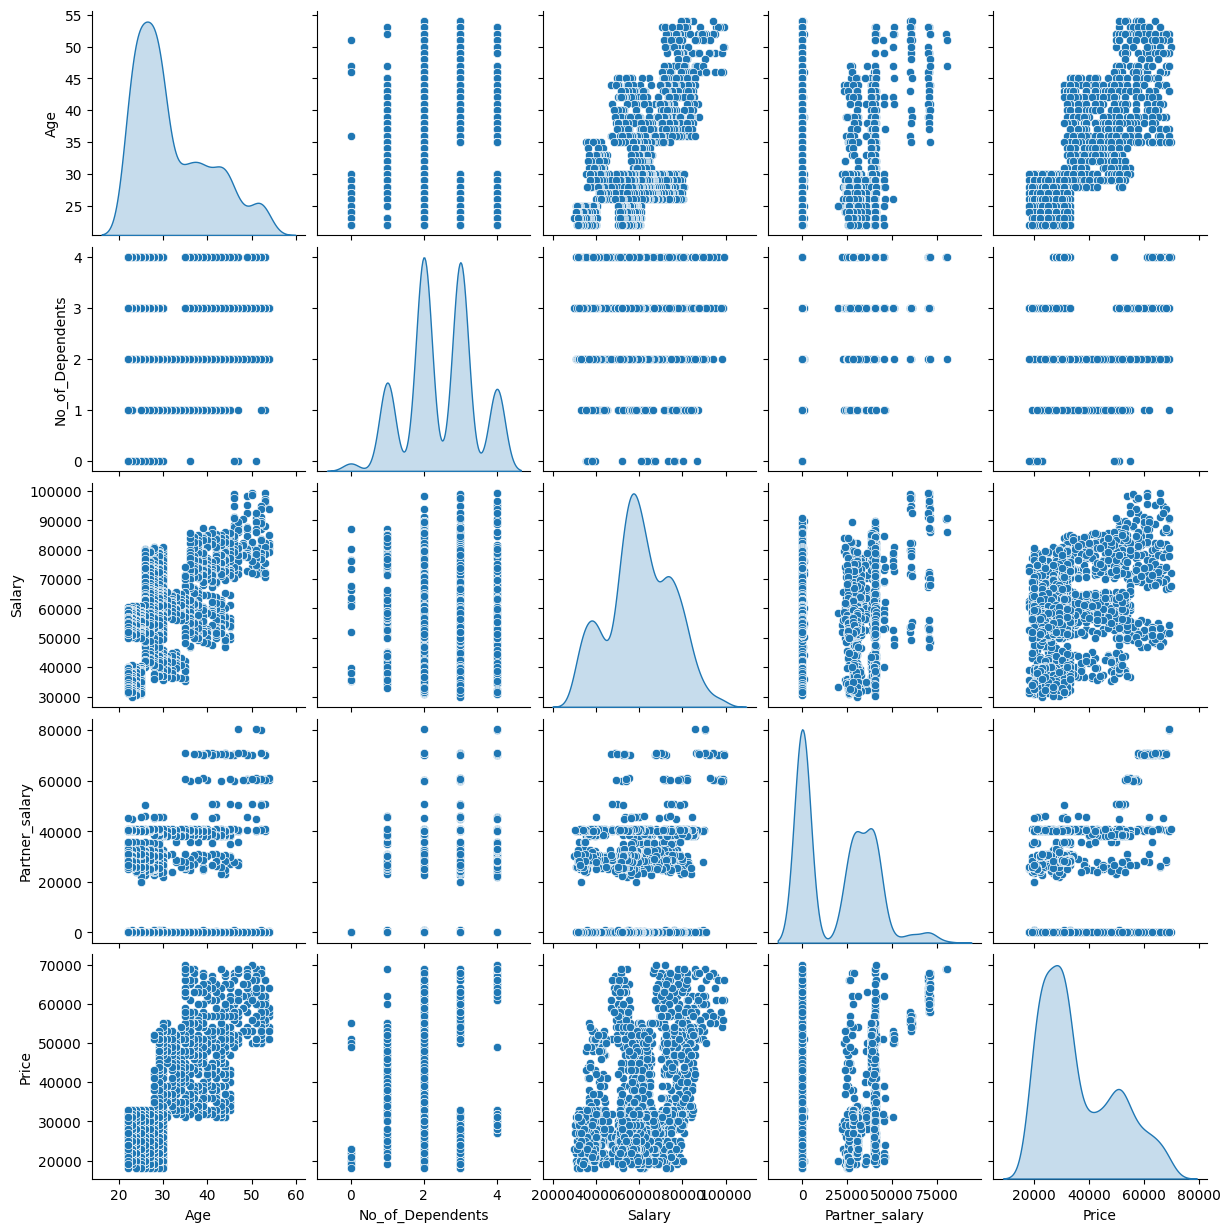

In [36]:
num_var = ['Age','No_of_Dependents','Salary','Partner_salary', 'Price']
sns.pairplot(data=df[num_var], diag_kind="kde")
plt.show()

**The pairplot visually confirms the correlations observed in the heatmap, particularly the strong positive relationships between Age & Salary and Salary & Price.**

# **Bivariate Analysis between strongest correlated variables**

<Figure size 600x400 with 0 Axes>

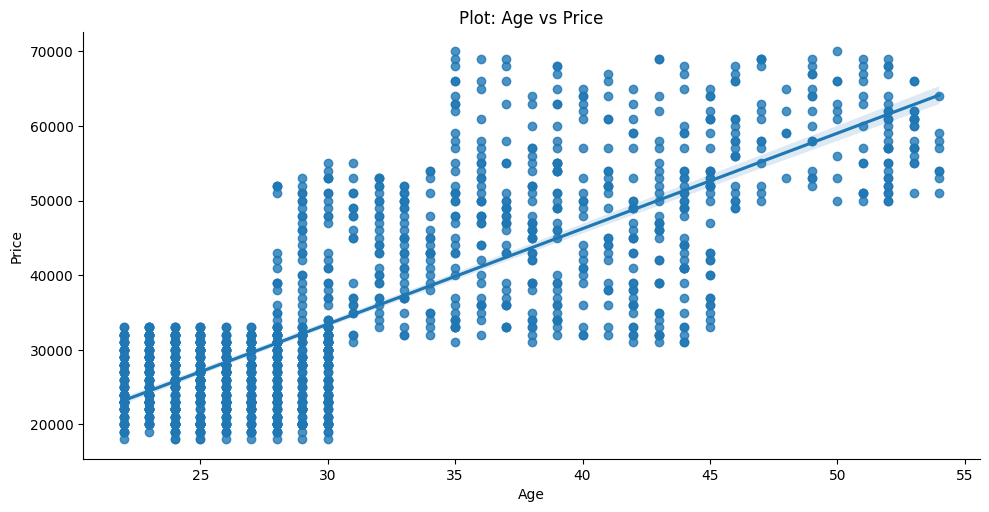

In [37]:
#1. Age vs Price
plt.figure(figsize=(6, 4))
sns.lmplot(data=df, x='Age', y='Price',height=5,aspect=2)
plt.title('Plot: Age vs Price')
plt.show()

<Figure size 600x400 with 0 Axes>

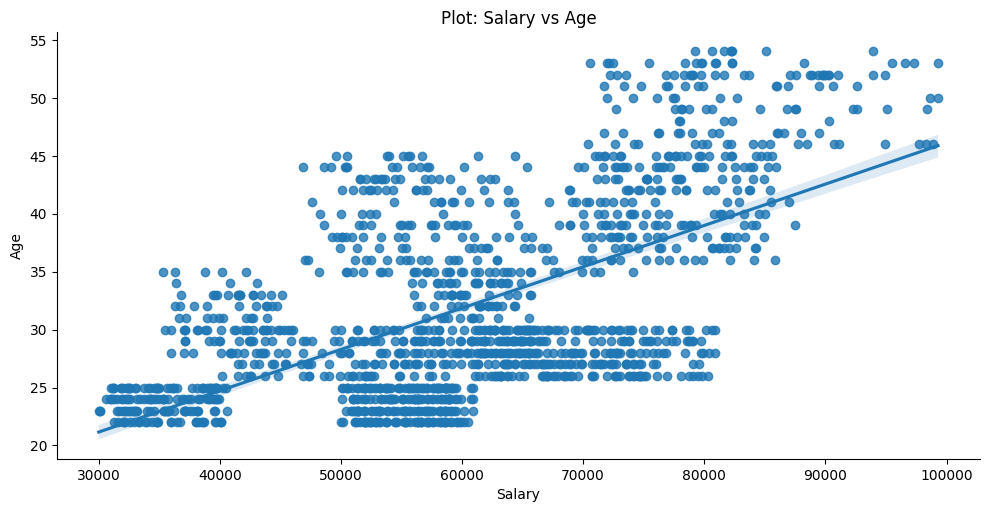

In [38]:
# 2. Salary vs Age
plt.figure(figsize=(6, 4))
sns.lmplot(data=df, x='Salary', y='Age',height=5,aspect=2)
plt.title('Plot: Salary vs Age')
plt.show()

<Figure size 1500x700 with 0 Axes>

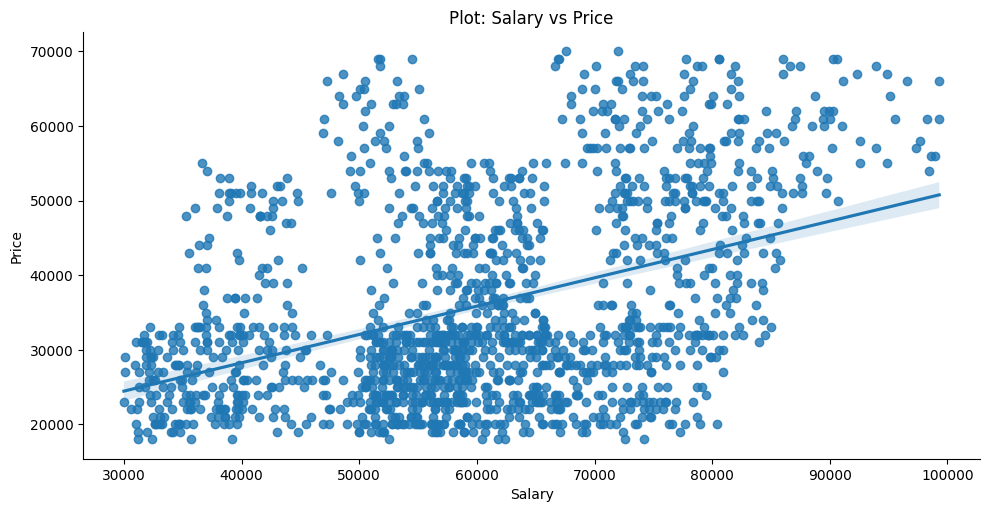

In [39]:
# 3. Salary vs Price
plt.figure(figsize=(15, 7))
sns.lmplot(data=df, x='Salary', y='Price',height=5,aspect=2)
plt.title('Plot: Salary vs Price')
plt.show()

**Fig 1 – Age vs Price**

Clear positive linear trend: vehicle price rises steadily with age.

Slope ≈ 800 ₹ per year (visual estimate).

Practical insight Older buyers represent the high-ticket segment; premium models or upsell packages should target 40 + customers.

**Fig 2 – Salary vs Age**

Moderate upward trend consistent with career progression.

Spread widens after ~₹70 k — senior roles have more salary dispersion.

**Fig 3 – Salary vs Price**

Positive but weaker relationship than Age-Price: many mid-salary buyers still choose inexpensive cars.

Clusters — two loose bands are visible:

₹30 k–45 k salary buyers concentrated below ₹40 k price.

₹60 k + salary buyers spread widely up to ₹70 k price.

Business takeaway: Salary alone is not a strong price determinant; financing options and life-stage (age) matter more.

**Overall Insights**

*Age is a stronger spending predictor than salary.*
Older customers consistently purchase higher-priced vehicles, even when salaries overlap with younger cohorts.

*Salary explains career progression but not all buying power.*
Many mid-salary individuals still opt for lower-priced models, suggesting conservatism or loan aversion.

These focused plots corroborate the heat-map findings and will inform our feature selection and segmentation strategy in the subsequent analysis steps.

**Categorical values vs Numerical values bivariate analysis**

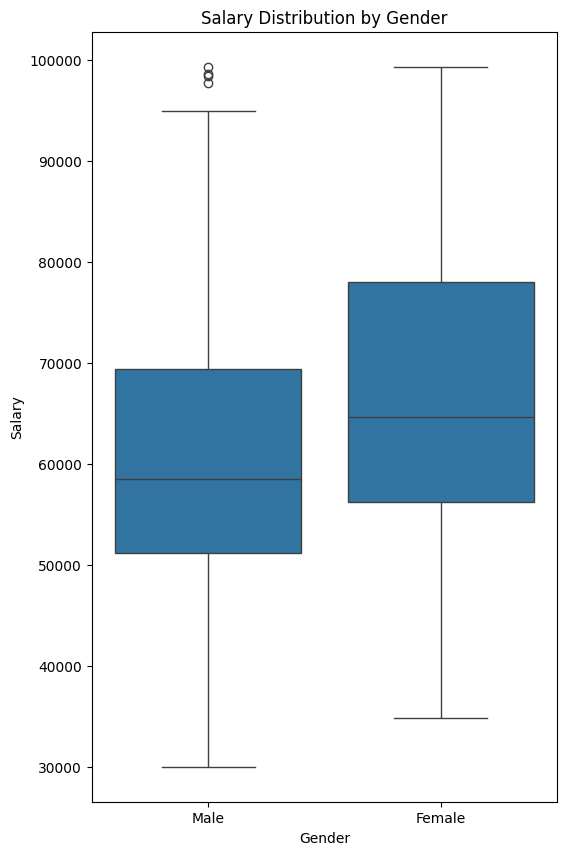

In [40]:
plt.figure(figsize=(6,10))
sns.boxplot(x='Gender', y='Salary', data=df)
plt.title('Salary Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Salary')
plt.show()

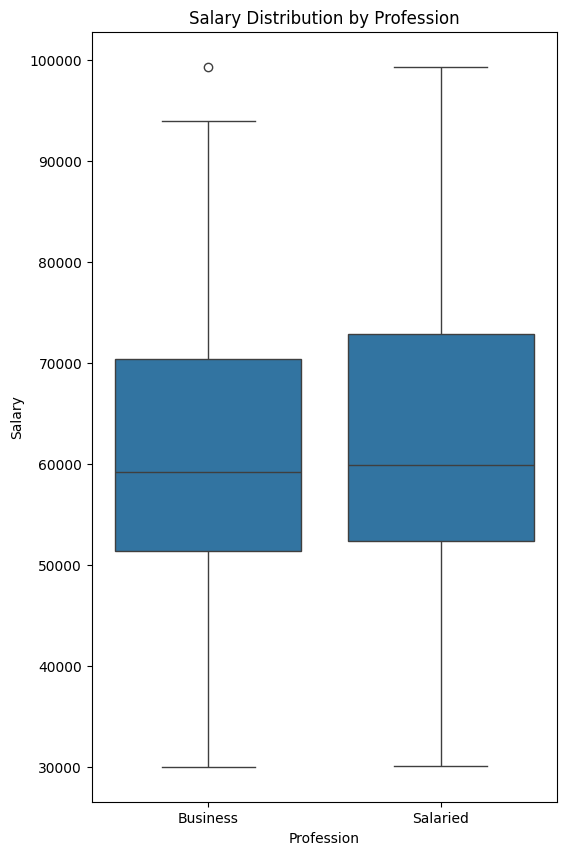

In [41]:
plt.figure(figsize=(6,10))
sns.boxplot(x='Profession', y='Salary', data=df)
plt.title('Salary Distribution by Profession')
plt.xlabel('Profession')
plt.ylabel('Salary')
plt.show()

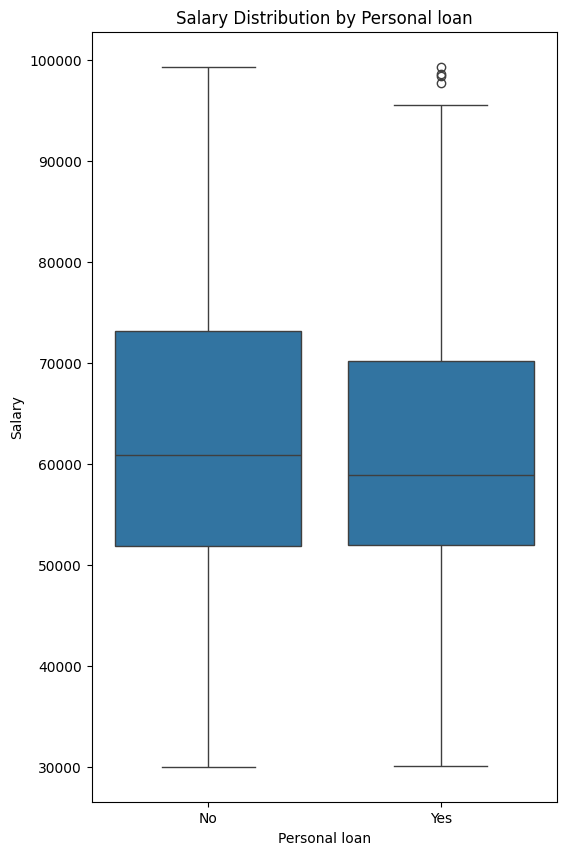

In [42]:
plt.figure(figsize=(6,10))
sns.boxplot(x='Personal_loan', y='Salary', data=df)
plt.title('Salary Distribution by Personal loan')
plt.xlabel('Personal loan')
plt.ylabel('Salary')
plt.show()

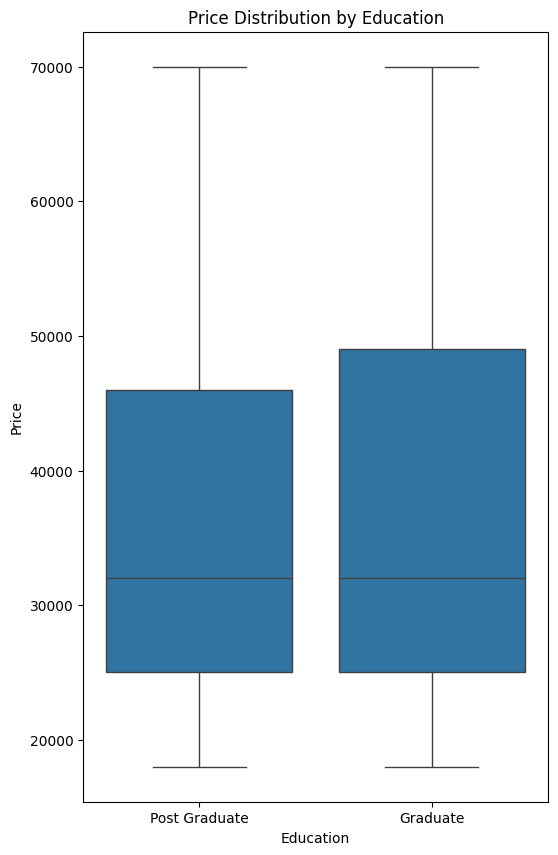

In [43]:
plt.figure(figsize=(6,10))
sns.boxplot(x='Education', y='Price', data=df)
plt.title('Price Distribution by Education')
plt.xlabel('Education')
plt.ylabel('Price')
plt.show()

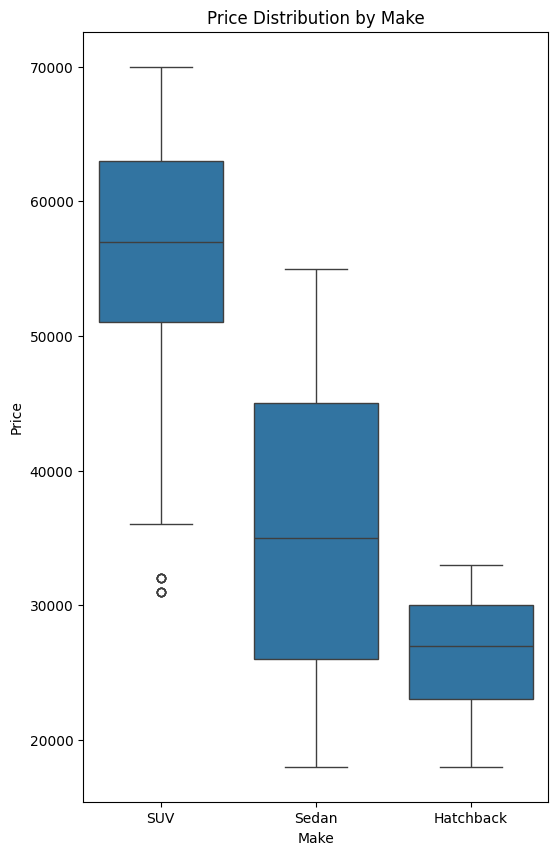

In [44]:
plt.figure(figsize=(6,10))
sns.boxplot(x='Make', y='Price', data=df)
plt.title('Price Distribution by Make')
plt.xlabel('Make')
plt.ylabel('Price')
plt.show()

**Price vs Make**

Box plot reveals that:

SUVs have the highest median price.

Sedans are priced mid-range.

Hatchbacks are generally low-cost.

This suggests a clear segmentation of the market by car type.

**Price vs Education**

Median price is nearly the same for both Graduate and Post Graduate groups.

This implies education level has minimal impact on the amount spent on cars.

**Salary vs Personal Loan**

Median salaries for customers with and without personal loans are similar.

This indicates personal loan decisions are not driven by income, but potentially by spending habits or other factors.

**Salary vs Profession**

Salaried and Business professionals show similar salary distributions.

High-income outliers exist in both categories.

**Salary vs Gender**

Median salary of females is slightly higher than that of males.

Gender does not create a major divide in income in this sample, suggesting marketing and financing offers should be gender-neutral.

# **Exploring the data to answer key questions using bivariate analysis**

**Q1. Do men tend to prefer SUVs more compared to women?**

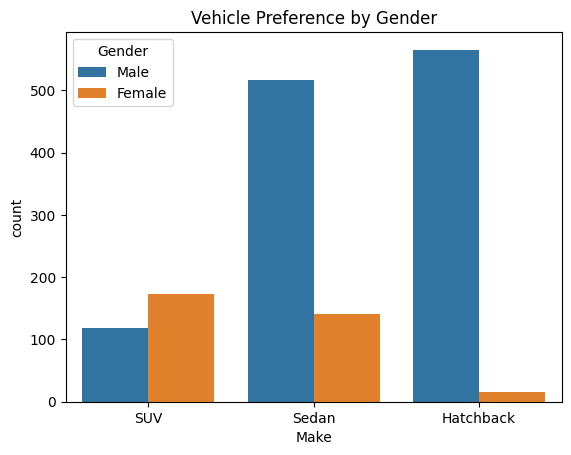

Make,Hatchback,SUV,Sedan
Gender,,,
Female,4.559271,52.583587,42.857143
Male,47.122602,9.841535,43.035863


In [45]:
sns.countplot(data=df, x='Make', hue='Gender')
plt.title("Vehicle Preference by Gender")
plt.show()

pd.crosstab(df['Gender'], df['Make'], normalize='index') * 100

To answer this, we performed a bivariate analysis between the categorical variables: Make (vehicle type) and Gender.

We used a countplot to visualize the distribution of vehicle preferences by gender.

We created a normalized crosstab to compute the percentage distribution of each vehicle type within each gender.

A majority of females (52.6%) prefer SUVs, while only 9.8% of males prefer them.

On the contrary, males heavily prefer Hatchbacks (47.1%), whereas only 4.6% of females prefer them.

Sedans are roughly equally preferred by both genders (~43%).

**Conclusion:**
No, men do not tend to prefer SUVs more than women.

In fact, the data shows that SUVs are significantly more popular among women, while men tend to prefer Hatchbacks instead.



**Q2. What is the likelihood of a salaried person buying a Sedan?**

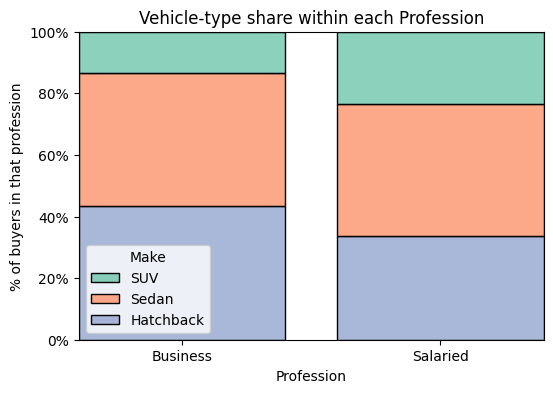

Make
Sedan        42.824074
Hatchback    33.680556
SUV          23.495370
Name: proportion, dtype: float64


In [46]:
plt.figure(figsize=(6,4))
sns.histplot(
    data=df,
    x='Profession',
    hue='Make',
    multiple='fill',
    shrink=.8,
    palette='Set2'
)
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.title('Vehicle-type share within each Profession')
plt.ylabel('% of buyers in that profession')
plt.xlabel('Profession')
plt.show()

salaried_df = df[df['Profession'] == 'Salaried']
salaried_vehicle_distribution = salaried_df['Make'].value_counts(normalize=True) * 100
print(salaried_vehicle_distribution)



≈ 43 % of salaried buyers choose a Sedan.

Hatchbacks trail at ~34 %, SUVs at ~23 %.

Therefore, the likelihood (probability) that a randomly selected salaried customer in this dataset buys a Sedan is about 1 in 2.3.

**Business take-away:** Sedans are the dominant choice among salaried professionals; marketing bundles or financing plans aimed at this segment should prioritise Sedan models.

**Q3. What evidence or data supports Sheldon Cooper's claim that a salaried male is an easier target for a SUV sale over a Sedan sale?**

In [47]:
pd.crosstab(df['Gender'], df['Make'], normalize='index') * 100

Make,Hatchback,SUV,Sedan
Gender,,,
Female,4.559271,52.583587,42.857143
Male,47.122602,9.841535,43.035863


In [48]:
pd.crosstab(df['Profession'], df['Make'], normalize='index') * 100

Make,Hatchback,SUV,Sedan
Profession,,,
Business,43.524096,13.253012,43.222892
Salaried,33.680556,23.495370,42.824074


Based on our previous bivariate analysis, Sheldon Cooper's claim is not supported by the data. Let’s look at the evidence:

Females overwhelmingly prefer SUVs (52.6%).
Males only show 9.8% SUV preference they heavily prefer Hatchbacks and Sedans.

Even among salaried individuals, the SUV share is lowest (23.5%), with Sedan being the top choice.

**Conclusion:**

No evidence supports the idea that a salaried male is an easier SUV sale.
In fact, both the gender and profession trends indicate that:

Males lean toward Hatchbacks and Sedans

SUVs appeal more to females than males

Salaried individuals show higher preference for Sedans

Thus, Sheldon Cooper is wrong — at least according to this dataset.



**Q4. How does the the amount spent on purchasing automobiles vary by gender?**

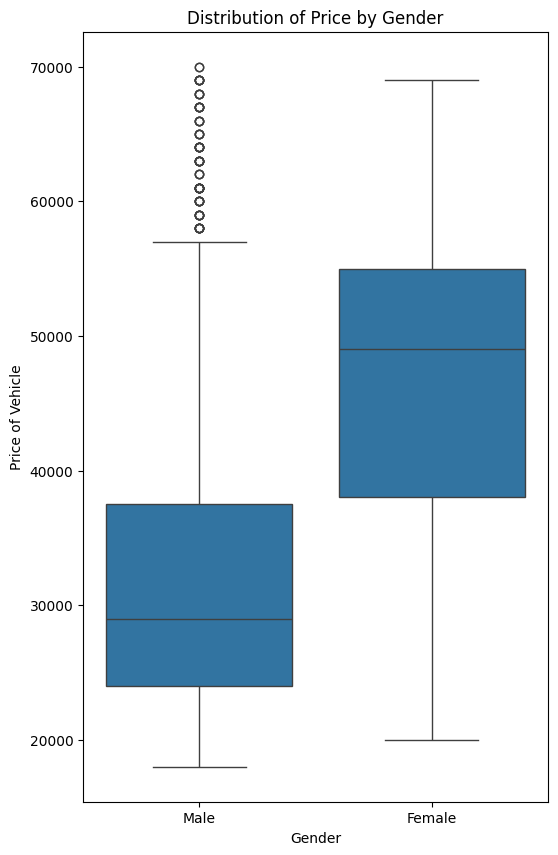

,count,mean,std,min,25%,50%,75%,max
Gender,,,,,,,,
Female,329.0,47705.167173,11244.836378,20000.0,38000.0,49000.0,55000.0,69000.0
Male,1199.0,32817.347790,12299.239195,18000.0,24000.0,29000.0,37500.0,70000.0


In [49]:
plt.figure(figsize=(6,10))
sns.boxplot(data=df, x='Gender', y='Price')
plt.title('Distribution of Price by Gender')
plt.ylabel('Price of Vehicle')
plt.xlabel('Gender')
plt.show()
df.groupby('Gender')['Price'].describe()

**Observations**

Females spend markedly more.

Median purchase price for women is ₹49 k, vs ₹29 k for men.

Mean price shows the same gap (≈ ₹47.7 k vs ₹32.8 k).

Distribution shift, not just outliers.

The entire IQR for females (38 k – 55 k) sits above the male IQR (24 k – 37.5 k).

Both groups share similar upper limits (~ ₹70 k), so females are not skewed by a few luxury buyers—they systematically buy dearer vehicles.

Sample-size note.

Males outnumber females 3.6 : 1, yet still spend less per vehicle on average.

**Conclusion**
Women in this dataset spend roughly ₹17 k more per vehicle than men (median basis).
They form a smaller segment but represent higher-revenue transactions. Marketing higher-trim models, premium features and extended‐warranty bundles toward female buyers could lift overall revenue.



**Q5. How much money was spent on purchasing automobiles by individuals who took a personal loan?**

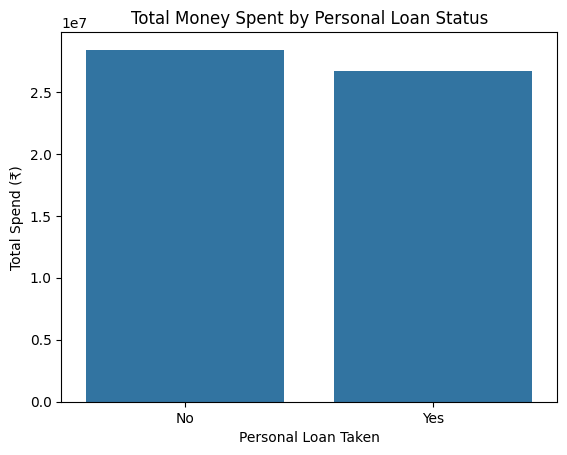

,Total_Spend,Avg_Spend,Count
Personal_loan,,,
No,28399000,37367.105263,760
Yes,26644000,34692.708333,768


Total amount spent by personal-loan customers: ₹26,644,000


In [50]:
loan_spend = df.groupby('Personal_loan')['Price'].sum().reset_index()
sns.barplot(data=loan_spend, x='Personal_loan', y='Price')
plt.title('Total Money Spent by Personal Loan Status')
plt.ylabel('Total Spend (₹)')
plt.xlabel('Personal Loan Taken')
plt.show()

spend_summary = (df.groupby('Personal_loan')['Price'].agg(Total_Spend='sum',Avg_Spend='mean',Count='size'))
display(spend_summary)

total_spend_loan = spend_summary.loc['Yes', 'Total_Spend']
print(f"Total amount spent by personal-loan customers: ₹{total_spend_loan:,.0f}")

**Observations**

Total outlay: Personal-loan customers spent ₹ 26.6 million on vehicles— only ~6 % less than the non-loan group, even though their average ticket price is lower.

Average ticket size: Loan takers spend ≈ ₹ 2.7 k less per buyer than cash buyers (₹ 34.7 k vs ₹ 37.4 k).

Volume compensates: The loan group’s slightly larger head-count (768 vs 760) almost offsets the lower per-car price, producing nearly comparable total revenue.

**Insight**

Personal-loan financing drives almost half of total sales revenue.
Although each financed purchase is a bit cheaper, the sheer number of loan buyers keeps their aggregate spend nearly on par with cash buyers. Offering attractive personal-loan packages is therefore critical to sustaining volume.

**Q6. How does having a working partner influence the purchase of higher-priced cars?**

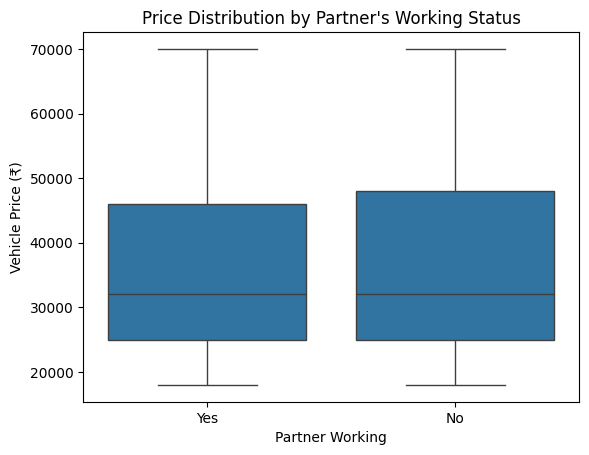

,count,mean,std,min,25%,50%,75%,max
Partner_working,,,,,,,,
No,690.0,36378.260870,13747.583185,18000.0,25000.0,32000.0,48000.0,70000.0
Yes,838.0,35730.310263,13366.493269,18000.0,25000.0,32000.0,46000.0,70000.0


In [51]:
sns.boxplot(data=df, x='Partner_working', y='Price')
plt.title("Price Distribution by Partner's Working Status")
plt.ylabel("Vehicle Price (₹)")
plt.xlabel("Partner Working")
plt.show()
df.groupby('Partner_working')['Price'].describe()

**Observations:**

The average vehicle price is slightly higher for individuals whose partners are not working (₹36,378 vs ₹35,730).

However, the median price is exactly the same in both groups (₹32,000), suggesting similar central tendencies.

The maximum price is ₹70,000 in both groups.

The distribution spread is comparable as shown in the boxplot.

**Visualization:**

A boxplot was used to compare the price distribution by partner working status.

The boxplots confirm that both groups have similar distributions with minor differences in upper quartiles.

**Conclusion:**

Having a working partner does not significantly influence the purchase of higher-priced cars. Both groups show similar price ranges, medians, and distributions.